<a href="https://colab.research.google.com/github/ajohana790-gif/detective-de-se-ales./blob/main/Detective%20de%20se%C3%B1ales_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Generando señales y dataset...

--- ¡Semana 1 completada con éxito! ---
Forma total del dataset con ruido: (4000, 100)
Datos de Entrenamiento (80%): 3200 muestras
Datos de Prueba (20%): 800 muestras


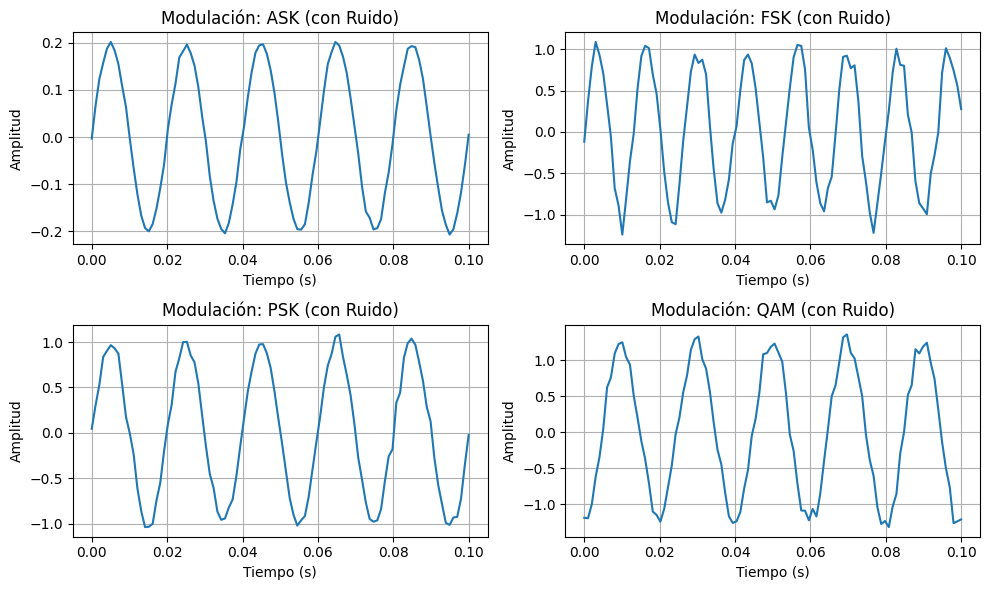


--- INICIANDO FASE 2: DISEÑO Y ENTRENAMIENTO ---
Forma de entrada para la CNN: (3200, 100, 1)
Clases mapeadas: {np.str_('ASK'): 0, np.str_('FSK'): 1, np.str_('PSK'): 2, np.str_('QAM'): 3}


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_2 (Conv1D)               │ (None, 96, 32)         │           192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_2 (MaxPooling1D)  │ (None, 48, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_3 (Conv1D)               │ (None, 44, 64)         │        10,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_3 (MaxPooling1D)  │ (None, 22, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1408)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │        90,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 100,932 (394.27 KB)

 Trainable params: 100,932 (394.27 KB)

 Non-trainable params: 0 (0.00 B)


Entrenando la Red Neuronal...
Epoch 1/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 9s 54ms/step - accuracy: 0.7847 - loss: 0.5823 - val_accuracy: 0.8025 - val_loss: 0.4335
Epoch 2/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 7s 24ms/step - accuracy: 0.8209 - loss: 0.3611 - val_accuracy: 0.8425 - val_loss: 0.3064
Epoch 3/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - accuracy: 0.8369 - loss: 0.3146 - val_accuracy: 0.8300 - val_loss: 0.3084
Epoch 4/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 3s 25ms/step - accuracy: 0.8525 - loss: 0.2869 - val_accuracy: 0.8662 - val_loss: 0.2842
Epoch 5/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.8466 - loss: 0.2977 - val_accuracy: 0.8363 - val_loss: 0.2674
Epoch 6/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.8475 - loss: 0.2708 - val_accuracy: 0.8662 - val_loss: 0.2639
Epoch 7/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.8475 - loss: 0.2704 - val_accuracy: 0.8487 - val_loss: 0.2370
Epoch 8/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0

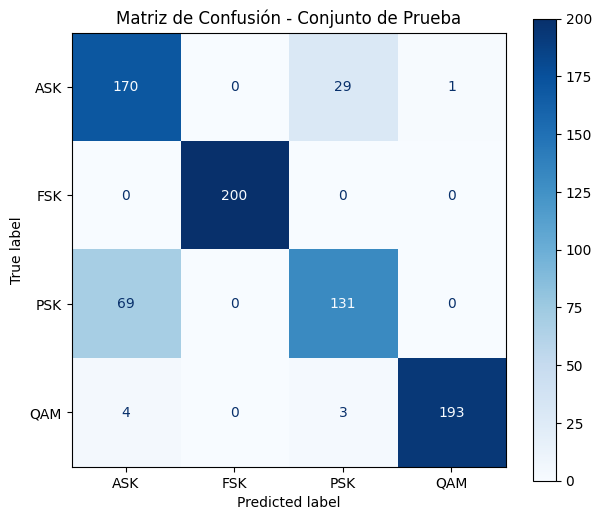

SNR =  -5 dB  -->  Precisión: 73.75%
SNR =   0 dB  -->  Precisión: 81.25%
SNR =   5 dB  -->  Precisión: 85.75%
SNR =  10 dB  -->  Precisión: 86.88%
SNR =  15 dB  -->  Precisión: 86.12%
SNR =  20 dB  -->  Precisión: 86.88%
SNR =  25 dB  -->  Precisión: 85.50%
SNR =  30 dB  -->  Precisión: 87.00%


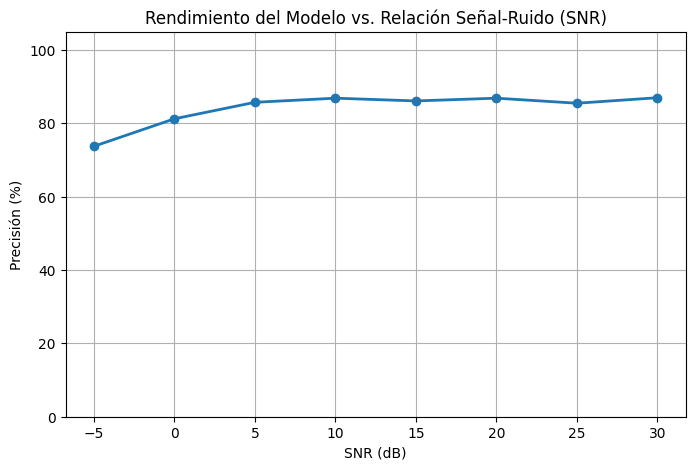

In [2]:
"""Johana Arevalo Tlacoxolal   Grupo: 5402"""
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, accuracy_score
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.utils import to_categorical

fs = 1000
fc = 50
num_muestras_por_tipo = 1000
t = np.linspace(0, 0.1, 100)

X_data = []
y_data = []

def generar_ask(fc, t):
    amplitud = np.random.choice([0.2, 1.0])
    return amplitud * np.sin(2 * np.pi * fc * t)

def generar_fsk(fc, t):
    f_shift = np.random.choice([fc * 0.5, fc * 1.5])
    return np.sin(2 * np.pi * f_shift * t)

def generar_psk(fc, t):
    fase = np.random.choice([0, np.pi])
    return np.sin(2 * np.pi * fc * t + fase)

def generar_qam(fc, t):
    amp = np.random.uniform(0.5, 1.5)
    fase = np.random.uniform(0, 2 * np.pi)
    return amp * np.sin(2 * np.pi * fc * t + fase)

print("Generando señales y dataset...")

modulaciones = {
    'ASK': generar_ask,
    'FSK': generar_fsk,
    'PSK': generar_psk,
    'QAM': generar_qam
}

for etiqueta, func in modulaciones.items():
    for _ in range(num_muestras_por_tipo):
        senal = func(fc, t)
        X_data.append(senal)
        y_data.append(etiqueta)

X_data = np.array(X_data)
y_data = np.array(y_data)

def agregar_awgn(senal, snr_db):
    potencia_senal = np.mean(senal ** 2)
    snr_lineal = 10 ** (snr_db / 10)
    potencia_ruido = potencia_senal / snr_lineal
    ruido = np.random.normal(0, np.sqrt(potencia_ruido), senal.shape)
    return senal + ruido

X_ruidoso = np.array([agregar_awgn(s, np.random.uniform(5, 30)) for s in X_data])

X_train, X_test, y_train, y_test = train_test_split(
    X_ruidoso, y_data, test_size=0.20, random_state=42, stratify=y_data
)

print("\n--- ¡Semana 1 completada con éxito! ---")
print(f"Forma total del dataset con ruido: {X_ruidoso.shape}")
print(f"Datos de Entrenamiento (80%): {X_train.shape[0]} muestras")
print(f"Datos de Prueba (20%): {X_test.shape[0]} muestras")

plt.figure(figsize=(10, 6))
for i, etiqueta in enumerate(modulaciones.keys()):
    idx = np.where(y_data == etiqueta)[0][0]
    plt.subplot(2, 2, i + 1)
    plt.plot(t, X_ruidoso[idx])
    plt.title(f"Modulación: {etiqueta} (con Ruido)")
    plt.xlabel("Tiempo (s)")
    plt.ylabel("Amplitud")
    plt.grid(True)

plt.tight_layout()
plt.show()

print("\n--- INICIANDO FASE 2: DISEÑO Y ENTRENAMIENTO ---")

encoder = LabelEncoder()
y_train_encoded = encoder.fit_transform(y_train)
y_test_encoded = encoder.transform(y_test)

X_train_cnn = np.expand_dims(X_train, axis=-1)
X_test_cnn = np.expand_dims(X_test, axis=-1)

num_clases = len(encoder.classes_)
y_train_cat = to_categorical(y_train_encoded, num_classes=num_clases)
y_test_cat = to_categorical(y_test_encoded, num_classes=num_clases)

print(f"Forma de entrada para la CNN: {X_train_cnn.shape}")
print(f"Clases mapeadas: {dict(zip(encoder.classes_, range(num_clases)))}")

longitud_senal = X_train_cnn.shape[1]

modelo = models.Sequential([
    layers.Input(shape=(longitud_senal, 1)),
    layers.Conv1D(filters=32, kernel_size=5, activation='relu'),
    layers.MaxPooling1D(pool_size=2),

    layers.Conv1D(filters=64, kernel_size=5, activation='relu'),
    layers.MaxPooling1D(pool_size=2),

    layers.Flatten(),
    layers.Dense(64, activation='relu'),

    layers.Dense(num_clases, activation='softmax')
])

modelo.summary()

modelo.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("\nEntrenando la Red Neuronal...")
historial = modelo.fit(
    X_train_cnn, y_train_cat,
    epochs=20,
    batch_size=32,
    validation_data=(X_test_cnn, y_test_cat),
    verbose=1
)

nombre_archivo = 'detective_senales_cnn.keras'
modelo.save(nombre_archivo)
print(f"\n--- ¡Fase 2 terminada! Modelo guardado como '{nombre_archivo}' ---")

print("\n--- INICIANDO FASE 3: EVALUACIÓN Y ROBUSTEZ ---")

y_pred_probs = modelo.predict(X_test_cnn, verbose=0)
y_pred_encoded = np.argmax(y_pred_probs, axis=1)

acc_general = accuracy_score(y_test_encoded, y_pred_encoded)
print(f"Precisión general en X_test: {acc_general * 100:.2f}%")

print("\nReporte por clase (Análisis de errores):")
print(classification_report(y_test_encoded, y_pred_encoded, target_names=encoder.classes_))

cm = confusion_matrix(y_test_encoded, y_pred_encoded)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=encoder.classes_)

fig, ax = plt.subplots(figsize=(7, 6))
disp.plot(ax=ax, cmap='Blues', values_format='d')
plt.title("Matriz de Confusión - Conjunto de Prueba")
plt.show()

niveles_snr = [-5, 0, 5, 10, 15, 20, 25, 30]
precisiones_snr = []

X_test_limpio = []
for etiqueta in y_test:
    senal_limpia = modulaciones[etiqueta](fc, t)
    X_test_limpio.append(senal_limpia)
X_test_limpio = np.array(X_test_limpio)

for snr in niveles_snr:
    X_test_snr = np.array([agregar_awgn(s, snr) for s in X_test_limpio])
    X_test_snr_cnn = np.expand_dims(X_test_snr, axis=-1)

    preds = np.argmax(modelo.predict(X_test_snr_cnn, verbose=0), axis=1)
    acc = accuracy_score(y_test_encoded, preds)
    precisiones_snr.append(acc * 100)
    print(f"SNR = {snr:3d} dB  -->  Precisión: {acc * 100:.2f}%")

plt.figure(figsize=(8, 5))
plt.plot(niveles_snr, precisiones_snr, marker='o', linewidth=2)
plt.title("Rendimiento del Modelo vs. Relación Señal-Ruido (SNR)")
plt.xlabel("SNR (dB)")
plt.ylabel("Precisión (%)")
plt.ylim(0, 105)
plt.grid(True)
plt.show()